# 07 Ablation, error analysis and a second dataset

**Project question.** With a limited marketing budget, which customers should receive an SMS so that it creates the most additional purchases?

**This notebook.** Notebooks 05 and 06 showed that ranking clients by the X-learner's predicted uplift finds the clients the SMS moves. Here we ask what that ranking relies on and where it fails. Feature groups are removed one at a time (ablation), the ranking is checked inside client groups (error analysis), and the same methods are tried on a second randomized experiment (Criteo). All X5 work uses the training folds with cross fitting.

**Summary.** The model that picks whom to text relies mostly on how customers have shopped recently and on their age; store and time of day habits add nothing, and less than half of the data gives a result that cannot be told apart from the full model. It finds the customers the message moves within every group of likely and unlikely buyers, but not among customers under 30. On a second, unrelated experiment with online ads, the same methods again found the people the ads moved, but there the most likely visitors were also good to target, which shows why each campaign needs its own test.

**Research question.** Which information does the uplift ranking need, where does it work, and do the methods behave the same way on another randomized experiment?

In [1]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import causalml.inference.tree  
from sklearn.model_selection import train_test_split

from x5uplift import plotting as P
from x5uplift.config import FEATURE_GROUPS_PATH, SEED, UPLIFT_PATH, UPLIFT_SCORES_PATH, CRITEO_SAMPLE_PATH
from x5uplift.modeling import load_experiment, model_matrix
from x5uplift.uplift import XLearner, bootstrap_metrics, cross_fit_uplift, summarize, ClassTransformation, SLearner, TLearner, UpliftForest, classifier, calibration_by_decile
from x5uplift.config import PROPENSITY_PATH, SEGMENTS_PATH
from x5uplift.experiment import diff_in_means

pd.set_option("display.width", 140)
P.set_style()

/Users/alper/Desktop/x5-uplift-targeting/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Failed to import duecredit due to No module named 'duecredit'


## 1. Ablation: which feature groups does the ranking need?

The X-learner is refitted with cross fitting on the training folds, once **without** each feature group and once with **only** that group. The change in AUUC against the full model (paired bootstrap) shows how much each group adds on top of the others; the single group models show how much each group carries on its own.

In [2]:
exp = load_experiment().merge(pd.read_parquet(UPLIFT_PATH), on="client_id", validate="one_to_one")
train = exp[exp["fold"] >= 0].reset_index(drop=True)
t, y, fold = (train[c].to_numpy() for c in ["treatment_flg", "target", "fold"])
groups = json.loads(FEATURE_GROUPS_PATH.read_text())
pd.Series({g: len(cols) for g, cols in groups.items()}, name="features")

demographics       7
rfm_trend         16
points             6
basket_content     3
stores             2
time_habits        2
categories        16
Name: features, dtype: int64

In [3]:
path = UPLIFT_SCORES_PATH.with_name("ablation_scores.parquet")
runs = pd.read_parquet(path) if path.exists() else pd.DataFrame({"client_id": train["client_id"]})
assert runs["client_id"].equals(train["client_id"])

all_cols = [c for cols in groups.values() for c in cols]
variants = {"All features": all_cols,
            **{f"Without {g}": [c for c in all_cols if c not in cols] for g, cols in groups.items()},
            **{f"Only {g}": cols for g, cols in groups.items()},
            "Compact: demographics and RFM": groups["demographics"] + groups["rfm_trend"],
            "Without stores and time habits": [c for c in all_cols if c not in groups["stores"] + groups["time_habits"]]}
for name, cols in variants.items():
    if name not in runs:
        start = time.time()
        runs[name] = (train["uplift"].to_numpy() if name == "All features"     # the notebook 05 model
                      else cross_fit_uplift(lambda: XLearner(seed=SEED), model_matrix(train, cols), t, y, fold))
        runs.to_parquet(path, index=False)
        print(f"{name}: {time.time() - start:.0f} s")

In [4]:
boot = bootstrap_metrics(y, t, {name: runs[name].to_numpy() for name in variants}, n_boot=300)
fmt = lambda s: (s["estimate"].map("{:.2f}".format) + " [" + s["ci_low"].map("{:.2f}".format) + ", "
                 + s["ci_high"].map("{:.2f}".format) + "]")
change = summarize(boot, reference="All features").xs("auuc", level="metric") * 100
alone = summarize(boot).xs("auuc", level="metric") * 100
pd.DataFrame({
    "AUUC change when removed": fmt(change.loc[[f"Without {g}" for g in groups]].rename(lambda n: n.removeprefix("Without "))),
    "AUUC with this group only": fmt(alone.loc[[f"Only {g}" for g in groups]].rename(lambda n: n.removeprefix("Only "))),
})

,AUUC change when removed,AUUC with this group only
model,,
demographics,"-0.12 [-0.24, -0.01]","0.37 [0.21, 0.50]"
rfm_trend,"-0.01 [-0.12, 0.10]","0.47 [0.33, 0.62]"
points,"-0.06 [-0.15, 0.04]","0.19 [0.05, 0.34]"
basket_content,"0.04 [-0.05, 0.12]","0.34 [0.19, 0.48]"
stores,"0.04 [-0.05, 0.11]","0.05 [-0.09, 0.20]"
time_habits,"0.03 [-0.05, 0.09]","0.06 [-0.09, 0.20]"
categories,"-0.06 [-0.16, 0.02]","0.32 [0.17, 0.48]"


In [5]:
fmt(summarize(boot, reference="All features").xs("auuc", level="metric")
    .loc[["Compact: demographics and RFM", "Without stores and time habits"]] * 100)

model
Compact: demographics and RFM     -0.08 [-0.20, 0.02]
Without stores and time habits    -0.02 [-0.09, 0.07]
dtype: object

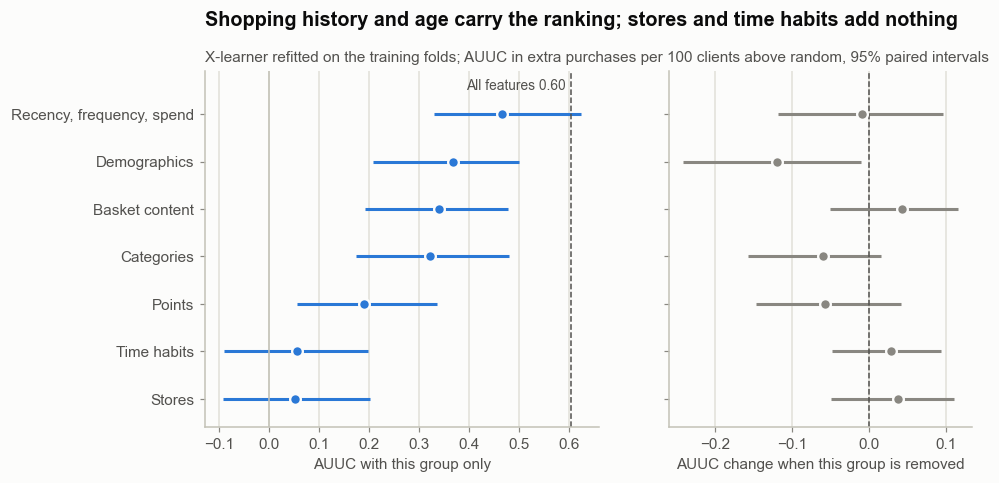

In [6]:
labels = {"demographics": "Demographics", "rfm_trend": "Recency, frequency, spend", "points": "Points",
          "basket_content": "Basket content", "stores": "Stores", "time_habits": "Time habits", "categories": "Categories"}
only = alone.loc[[f"Only {g}" for g in groups]].set_axis(list(groups)).sort_values("estimate")
drop = change.loc[[f"Without {g}" for g in groups]].set_axis(list(groups)).loc[only.index]
full = alone.loc["All features", "estimate"]
yl = [labels[g] for g in only.index]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 4.2), sharey=True, gridspec_kw={"width_ratios": [1.3, 1]})
a1.errorbar(only["estimate"], yl, xerr=[only["estimate"] - only["ci_low"], only["ci_high"] - only["estimate"]],
            fmt="o", color=P.BLUE, markersize=7, markeredgecolor=P.SURFACE, markeredgewidth=1.5, linewidth=2)
a1.axvline(full, color=P.INK_2, linewidth=1, linestyle="--")
a1.text(full - 0.01, len(yl) - 0.4, f"All features {full:.2f}", fontsize=9, color=P.INK_2, va="center", ha="right")
a1.axvline(0, color=P.AXIS, linewidth=1)
a1.set_xlabel("AUUC with this group only")
a2.errorbar(drop["estimate"], yl, xerr=[drop["estimate"] - drop["ci_low"], drop["ci_high"] - drop["estimate"]],
            fmt="o", color=P.MUTED, markersize=7, markeredgecolor=P.SURFACE, markeredgewidth=1.5, linewidth=2)
a2.axvline(0, color=P.INK_2, linewidth=1, linestyle="--")
a2.set_xlabel("AUUC change when this group is removed")
for a in (a1, a2):
    a.grid(axis="x", visible=True)
    a.grid(axis="y", visible=False)
a1.set_ylim(-0.6, len(yl) - 0.1)
P.titles(a1, "Shopping history and age carry the ranking; stores and time habits add nothing",
         "X-learner refitted on the training folds; AUUC in extra purchases per 100 clients above random, 95% paired intervals")
P.save(fig, "07_ablation")

Information overlaps between groups. On its own, shopping history (recency, frequency, spend) reaches an AUUC of 0.47 [0.33, 0.62], about 80% of the full model's 0.60; demographics, basket content and categories each reach 0.3 to 0.4; stores and time habits alone do not differ from random. Removing any single group changes little because others carry similar information; the only group whose removal costs a clear amount is demographics (−0.12 [−0.24, −0.01]), whose signal is mainly age, which notebook 04 found to change the effect independently of purchase probability. Removing stores and time habits together changes nothing (−0.02 [−0.09, 0.07]). A compact model with only demographics and shopping history (23 of 52 features) cannot be told apart from the full model (−0.08 [−0.20, 0.02]), though its estimate is lower; for a company, age and transaction history are the data to collect first.

## 2. Error analysis: where does the ranking work?

Two checks inside client groups (training folds, out of fold predictions of the full model):

* **Level:** does the average predicted uplift of a group match the effect observed between its SMS and control clients?
* **Ranking:** inside the group, does ranking by predicted uplift still beat random targeting (AUUC within the group)? This matters most inside bands of purchase probability: notebook 04 found that the effect falls with purchase probability, so a model that had learned only "unlikely buyers first" would score zero inside each band.

Groups with fewer than 2,000 clients (express point collectors, clients without a valid age) are left out.

In [7]:
score = runs["All features"].to_numpy()
p_buy = pd.read_parquet(PROPENSITY_PATH).set_index("client_id").loc[train["client_id"], "p_buy_without_sms"].to_numpy()
groupings = {
    "Segment": pd.read_parquet(SEGMENTS_PATH).set_index("client_id").loc[train["client_id"], "segment_name"].to_numpy(),
    "Age": pd.cut(train["age"], [13, 29, 39, 49, 59, 100], labels=["14 to 29", "30 to 39", "40 to 49", "50 to 59", "60 and over"]).astype(str).to_numpy(),
    "Purchase probability": pd.qcut(p_buy, 3, labels=["Low third", "Middle third", "High third"]).astype(str),
}
rows = []
for var, labels_ in groupings.items():
    for g in pd.unique(labels_):
        m = labels_ == g
        if m.sum() < 2000:
            continue
        auuc = summarize(bootstrap_metrics(y[m], t[m], {"model": score[m]}, n_boot=200)).loc[("model", "auuc")]
        eff = diff_in_means(y[m], t[m])
        rows.append({"variable": var, "group": g, "clients": int(m.sum()),
                     "predicted": 100 * score[m].mean(), "observed": 100 * eff["effect"],
                     "obs_low": 100 * eff["ci_low"], "obs_high": 100 * eff["ci_high"],
                     "auuc": 100 * auuc["estimate"], "auuc_low": 100 * auuc["ci_low"], "auuc_high": 100 * auuc["ci_high"]})
err = pd.DataFrame(rows).set_index(["variable", "group"])
print(f"Rank correlation between predicted uplift and purchase probability: {pd.Series(score).corr(pd.Series(p_buy), method='spearman'):.2f}")
err.round(2)

Rank correlation between predicted uplift and purchase probability: -0.43


clients  predicted  observed  obs_low  obs_high  auuc  auuc_low  auuc_high
variable             group                                                                                                   
Segment              Occasional shoppers             22689       3.89      3.90     2.68      5.11  0.29     -0.00       0.70
                     Regular small baskets           33392       3.90      4.14     3.09      5.19  0.52      0.21       0.79
                     Big basket shoppers             31765       2.56      2.58     1.53      3.63  0.32      0.00       0.58
                     Daily top-up shoppers           34090       2.14      1.47     0.77      2.16  0.38      0.15       0.59
                     Point redeemers                  7247       6.60      7.25     5.03      9.48  2.43      1.75       3.01
                     Alcohol and own brand buyers     9215       3.23      3.50     1.48      5.53  0.39     -0.18       0.97
Age                  40 to 49                        26894       3.09      2.76     1.59      3.93  0.71      0.37       1.02
                     60 and over                     34232       4.13      5.22     4.22      6.22  0.91      0.61       1.22
                     50 to 59                        24910       3.64      4.33     3.12      5.53  0.51      0.17       0.88
                     30 to 39                        31241       2.56      2.15     1.07      3.24  0.38      0.11       0.66
                     14 to 29                        22132       2.60      1.41     0.12      2.71 -0.10     -0.44       0.20
Purchase probability Low third                       46676       4.35      4.94     4.08      5.81  0.92      0.66       1.17
                     Middle third                    46675       3.29      3.04     2.17      3.92  0.33      0.07       0.56
                     High third                      46676       2.11      1.77     1.17      2.37  0.26      0.09       0.44

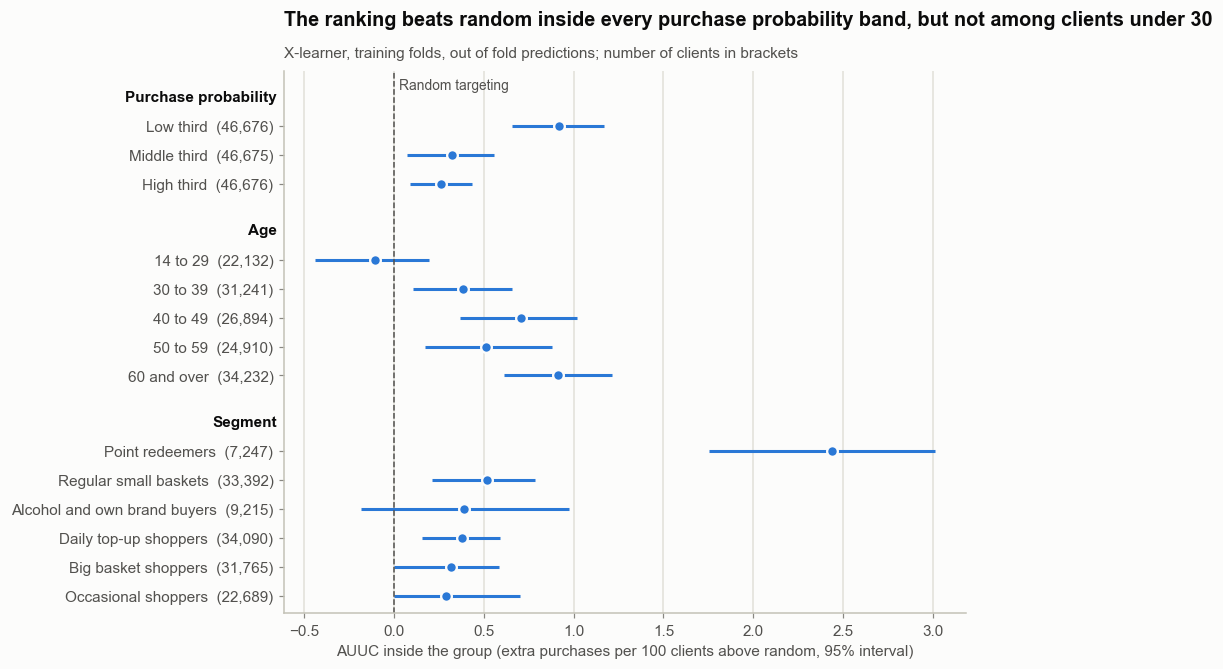

In [8]:
order = {"Purchase probability": ["Low third", "Middle third", "High third"],
         "Age": ["14 to 29", "30 to 39", "40 to 49", "50 to 59", "60 and over"]}
fig, ax = plt.subplots(figsize=(8, 6.4))
top, ticks, labels = 0, [], []
for var in ["Purchase probability", "Age", "Segment"]:
    b = err.loc[var]
    b = b.loc[order[var]] if var in order else b.sort_values("auuc", ascending=False)
    ax.text(-0.01, top, var, transform=ax.get_yaxis_transform(), ha="right", va="center", fontweight="bold")
    rows_ = top - 1 - np.arange(len(b))
    ax.errorbar(b["auuc"], rows_, xerr=[b["auuc"] - b["auuc_low"], b["auuc_high"] - b["auuc"]], fmt="o", color=P.BLUE,
                markersize=7, markeredgecolor=P.SURFACE, markeredgewidth=1.5, linewidth=2)
    ticks += list(rows_)
    labels += [f"{g}  ({n:,})" for g, n in zip(b.index, b["clients"])]
    top = rows_[-1] - 1.6
ax.axvline(0, color=P.INK_2, linewidth=1, linestyle="--")
ax.text(0.03, 0.4, "Random targeting", fontsize=9, color=P.INK_2, va="center")
ax.set_yticks(ticks, labels)
ax.set(ylim=(top + 1, 0.9), xlabel="AUUC inside the group (extra purchases per 100 clients above random, 95% interval)")
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
P.titles(ax, "The ranking beats random inside every purchase probability band, but not among clients under 30",
         "X-learner, training folds, out of fold predictions; number of clients in brackets")
P.save(fig, "07_error_analysis")

The ranking is more than "unlikely buyers first". Its rank correlation with purchase probability is −0.43, and inside each third of purchase probability it still beats random targeting (AUUC 0.92 [0.66, 1.17] in the low third, 0.33 [0.07, 0.56] in the middle, 0.26 [0.09, 0.44] in the high third). It also ranks inside every age band from 30 upwards and inside most segments, most strongly among point redeemers (2.43 [1.75, 3.01]). Its blind spot is clients under 30 (−0.10 [−0.44, 0.20]), where the effect itself is small. On level, predictions match the observed effect in most groups, but the model compresses the age pattern: it predicts 4.1 points for clients aged 60 and over, below their observed 5.2 [4.2, 6.2], and 2.6 for clients under 30 against an observed 1.4 [0.1, 2.7].

## 3. A second randomized experiment: Criteo

The Criteo uplift dataset (v2.1, Criteo AI Lab, CC BY-NC-SA 4.0) comes from randomized tests in online advertising: 12 anonymized features, a treatment flag (assigned to see ads, 85% of users) and whether the user visited the advertiser's site. A random 10% sample (1.4 million users, `scripts/05_sample_criteo.py`) is split 70/30, stratified by treatment and visit. The same methods are fitted on the 70% and evaluated on the 30%; the X-learner and class transformation use the 85% treated share, and the uplift forest is fitted on a 200,000 user subsample for time. The question is whether the patterns found in X5 hold: which methods rank best, and how ranking likely visitors first compares with random targeting.

In [9]:
cr = pd.read_parquet(CRITEO_SAMPLE_PATH)
feats = [f"f{i}" for i in range(12)]
tr, te = train_test_split(cr, test_size=0.3, random_state=SEED, stratify=cr["treatment"] * 2 + cr["visit"])
e = tr["treatment"].mean()
X_tr, t_tr, y_tr = tr[feats], tr["treatment"].to_numpy(), tr["visit"].to_numpy()
X_te, t_te, y_te = te[feats], te["treatment"].to_numpy(), te["visit"].to_numpy()

ate_c = diff_in_means(y_te, t_te)
print(f"Train {len(tr):,}, test {len(te):,}, treated share {e:.3f}")
print(f"Effect of the ads on visits (test): {100 * ate_c['effect']:.2f} points [{100 * ate_c['ci_low']:.2f}, {100 * ate_c['ci_high']:.2f}]")

Train 977,974, test 419,132, treated share 0.850
Effect of the ads on visits (test): 1.08 points [0.91, 1.24]


In [10]:
path_c = UPLIFT_SCORES_PATH.with_name("criteo_scores.parquet")
cs = pd.read_parquet(path_c) if path_c.exists() else pd.DataFrame(index=range(len(te)))
sub = np.random.default_rng(SEED).random(len(tr)) < 200_000 / len(tr)      # subsample for the slow forest
models = {
    "S-learner": lambda: SLearner(seed=SEED).fit(X_tr, t_tr, y_tr),
    "T-learner": lambda: TLearner(seed=SEED).fit(X_tr, t_tr, y_tr),
    "X-learner": lambda: XLearner(seed=SEED, treatment_share=e).fit(X_tr, t_tr, y_tr),
    "Class transformation": lambda: ClassTransformation(seed=SEED, treatment_share=e).fit(X_tr, t_tr, y_tr),
    "Uplift forest": lambda: UpliftForest(seed=SEED).fit(X_tr[sub], t_tr[sub], y_tr[sub]),
}
for name, fit in models.items():
    if name not in cs:
        start = time.time()
        cs[name] = fit().predict(X_te)
        cs.to_parquet(path_c, index=False)
        print(f"{name}: {time.time() - start:.0f} s")
if "Visit probability" not in cs:      # reference: likely visitors first, from a control group model
    cs["Visit probability"] = classifier(SEED).fit(X_tr[t_tr == 0], y_tr[t_tr == 0]).predict_proba(X_te)[:, 1]
    cs.to_parquet(path_c, index=False)
cs.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
S-learner,419132.0,0.0072,0.0231,-0.1547,0.0002,0.0005,0.0027,0.3593
T-learner,419132.0,0.0079,0.0311,-0.3262,0.0001,0.0004,0.0029,0.5576
X-learner,419132.0,0.0078,0.0236,-0.1675,0.0016,0.0017,0.0031,0.4857
Class transformation,419132.0,0.0107,0.0204,-0.4513,0.0072,0.0072,0.0135,0.3054
Uplift forest,419132.0,0.1077,0.0140,0.0507,0.0946,0.1067,0.1099,0.1741
Visit probability,419132.0,0.0400,0.1080,0.0003,0.0006,0.0025,0.0147,0.8969


In [11]:
scores_c = {**{c: cs[c].to_numpy() for c in cs.columns}, "Random": np.random.default_rng(SEED).random(len(te))}
boot_c = bootstrap_metrics(y_te, t_te, scores_c, n_boot=200)

def fmt_ci(s):
    s = s * 100
    text = s["estimate"].map("{:.2f}".format) + " [" + s["ci_low"].map("{:.2f}".format) + ", " + s["ci_high"].map("{:.2f}".format) + "]"
    return text.unstack("metric").loc[list(scores_c)]

display(fmt_ci(summarize(boot_c)))
fmt_ci(summarize(boot_c, reference="X-learner")).drop(index=["X-learner", "Random"])

metric,auuc,uplift_top_10,uplift_top_20,uplift_top_30
model,,,,
S-learner,"0.36 [0.29, 0.42]","6.43 [5.28, 7.53]","4.12 [3.35, 4.78]","3.01 [2.45, 3.44]"
T-learner,"0.34 [0.27, 0.41]","6.24 [4.69, 7.42]","4.11 [3.38, 4.75]","2.96 [2.43, 3.39]"
X-learner,"0.35 [0.29, 0.42]","6.27 [4.87, 7.41]","3.96 [3.22, 4.57]","2.97 [2.46, 3.42]"
Class transformation,"0.29 [0.21, 0.34]","5.48 [4.11, 6.57]","3.68 [2.99, 4.36]","2.72 [2.19, 3.17]"
Uplift forest,"0.29 [0.24, 0.35]","5.09 [4.16, 5.80]","3.80 [3.18, 4.27]","2.81 [2.37, 3.19]"
Visit probability,"0.36 [0.29, 0.43]","4.76 [3.54, 6.11]","4.07 [3.26, 4.78]","3.08 [2.58, 3.56]"
Random,"-0.01 [-0.06, 0.03]","1.11 [0.65, 1.62]","1.11 [0.75, 1.47]","1.18 [0.88, 1.48]"


metric,auuc,uplift_top_10,uplift_top_20,uplift_top_30
model,,,,
S-learner,"0.01 [-0.04, 0.04]","0.16 [-0.56, 0.96]","0.15 [-0.20, 0.48]","0.04 [-0.20, 0.23]"
T-learner,"-0.01 [-0.08, 0.06]","-0.03 [-0.81, 0.85]","0.15 [-0.34, 0.58]","-0.01 [-0.29, 0.25]"
Class transformation,"-0.07 [-0.11, -0.01]","-0.79 [-1.49, 0.03]","-0.28 [-0.66, 0.17]","-0.24 [-0.49, 0.04]"
Uplift forest,"-0.06 [-0.12, 0.02]","-1.18 [-2.25, -0.18]","-0.16 [-0.66, 0.42]","-0.16 [-0.47, 0.19]"
Visit probability,"0.01 [-0.03, 0.06]","-1.51 [-2.41, -0.53]","0.11 [-0.28, 0.55]","0.12 [-0.09, 0.32]"


In [12]:
pd.concat({name: calibration_by_decile(y_te, t_te, cs[name])[["predicted", "effect", "ci_low", "ci_high"]] * 100
           for name in ["X-learner", "Uplift forest"]}, axis=1).round(2)

X-learner                       Uplift forest                      
   predicted effect ci_low ci_high     predicted effect ci_low ci_high
1       5.60   6.28   5.09    7.47         13.73   5.20   4.34    6.06
2       0.79   0.78   0.02    1.54         12.54   2.42   1.70    3.13
3       0.31   0.41  -0.06    0.87         10.91   0.52  -0.08    1.12
4       0.22   0.00  -0.31    0.31         10.71  -0.08  -0.19    0.02
5       0.17   0.20   0.03    0.37         10.67   0.05  -0.04    0.13
6       0.16  -0.04  -0.21    0.12         10.65   0.13  -0.01    0.26
7       0.16  -0.00  -0.12    0.12         10.50   0.66   0.36    0.96
8       0.16   0.01  -0.06    0.08          9.51   0.53  -0.01    1.06
9       0.16   0.05   0.01    0.09          9.31  -0.14  -0.70    0.43
10      0.02   0.34  -0.13    0.80          9.17   0.63   0.02    1.23

On Criteo, every uplift method beats random targeting clearly (AUUC 0.29 to 0.36 extra visits per 100 users against −0.01; in the top 10%, 6.3 points for the X-learner against 1.1 at random). As in X5, the S, T and X learners cannot be told apart, and class transformation (−0.07 [−0.11, −0.01] against the X-learner) and the uplift forest do no better. The effect is concentrated: the X-learner's top decile shows 6.3 points [5.1, 7.5] and most other deciles about zero, while in X5 the SMS moved most clients a little. The uplift forest's levels are biased on Criteo (about 9 to 10 points above the observed effect in every decile, cause not found, possibly the 85% treated share), so only its ranking is used. The main difference from X5: ranking likely visitors first works almost as well as the uplift models here (AUUC 0.36 [0.29, 0.43]), whereas in X5 ranking likely buyers first was worse than random.

In [13]:
def top10_ratio(y_, t_, scores):
    """Effect in the top 10% of each ranking divided by the average effect (interval of the top 10% only)."""
    s = summarize(bootstrap_metrics(y_, t_, scores, n_boot=200)).xs("uplift_top_10", level="metric")
    return s / (y_[t_ == 1].mean() - y_[t_ == 0].mean())

x5_oof = pd.read_parquet(UPLIFT_SCORES_PATH)                    # notebook 05, out of fold, seed 42
assert x5_oof["client_id"].equals(train["client_id"])
x5_scores = {c: x5_oof[c].to_numpy() for c in x5_oof.columns if c != "client_id"} | {"Likely buyers first": p_buy}
criteo_scores = ({c: cs[c].to_numpy() for c in cs.columns if c != "Visit probability"}
                 | {"Likely buyers first": cs["Visit probability"].to_numpy()})
ratios = {"X5 (SMS, purchase)": top10_ratio(y, t, x5_scores), "Criteo (ads, visit)": top10_ratio(y_te, t_te, criteo_scores)}
pd.concat(ratios, axis=1).round(2)

X5 (SMS, purchase)                Criteo (ads, visit)               
                               estimate ci_low ci_high            estimate ci_low ci_high
model                                                                                    
Class transformation               2.33   1.80    2.79                5.10   3.82    6.11
Likely buyers first                0.25   0.01    0.44                4.43   3.29    5.69
S-learner                          3.18   2.64    3.57                5.98   4.91    7.01
T-learner                          2.56   2.01    3.00                5.80   4.37    6.90
Uplift forest                      2.75   2.25    3.25                4.74   3.87    5.40
X-learner                          3.02   2.49    3.47                5.83   4.53    6.89

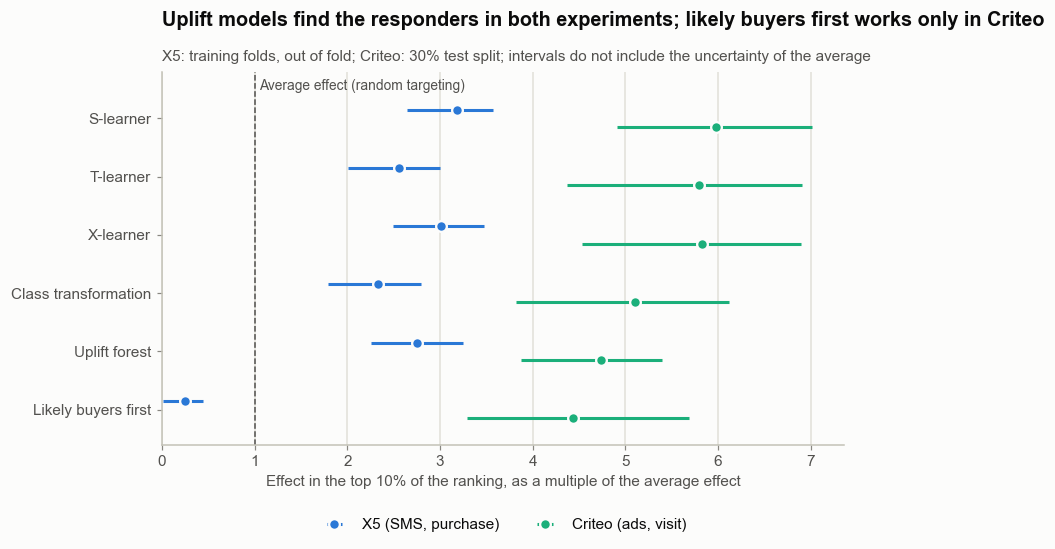

In [14]:
idx = ["S-learner", "T-learner", "X-learner", "Class transformation", "Uplift forest", "Likely buyers first"]
fig, ax = plt.subplots(figsize=(8, 4.4))
y0 = np.arange(len(idx))[::-1]
for (name, r), color, off in zip(ratios.items(), [P.BLUE, P.AQUA], [0.15, -0.15]):
    r = r.loc[idx]
    ax.errorbar(r["estimate"], y0 + off, xerr=[r["estimate"] - r["ci_low"], r["ci_high"] - r["estimate"]], fmt="o",
                color=color, markersize=7, markeredgecolor=P.SURFACE, markeredgewidth=1.5, linewidth=2, label=name)
ax.axvline(1, color=P.INK_2, linewidth=1, linestyle="--")
ax.text(1.05, len(idx) - 0.45, "Average effect (random targeting)", fontsize=9, color=P.INK_2, va="center")
ax.set_yticks(y0, idx)
ax.set(ylim=(-0.6, len(idx) - 0.2), xlim=(0, None), xlabel="Effect in the top 10% of the ranking, as a multiple of the average effect")
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
P.titles(ax, "Uplift models find the responders in both experiments; likely buyers first works only in Criteo",
         "X5: training folds, out of fold; Criteo: 30% test split; intervals do not include the uncertainty of the average")
P.save(fig, "07_x5_vs_criteo")

## Conclusion

**Answer.** The X5 ranking relies mainly on shopping history and age: shopping history alone reaches an AUUC of 0.47 of the full model's 0.60, removing demographics is the only removal with a clear cost (−0.12 [−0.24, −0.01]), and stores and time habits add nothing. The ranking works inside every band of purchase probability and every age band from 30 up, but not among clients under 30. On a second randomized experiment (Criteo, online ads), the same methods again find the people the treatment moves, with the same order between methods; what differs is the role of the baseline: ranking likely visitors first works there, while ranking likely buyers first failed in X5.

**What we learned**
* Information overlaps between feature groups: a compact model with demographics and shopping history (23 of 52 features) cannot be told apart from the full model (−0.08 [−0.20, 0.02]). Age and transaction history are the data to collect first.
* The ranking is not just "unlikely buyers first": its rank correlation with purchase probability is −0.43 and it beats random inside each third of purchase probability (0.92, 0.33 and 0.26).
* The model compresses the age pattern (4.1 points predicted against 5.2 observed for clients aged 60 and over, 2.6 against 1.4 under 30).
* In both datasets the S, T and X learners are close, class transformation and the uplift forest do not do better.
* Whether contacting the most likely buyers is a good or a bad policy depends on the campaign. Only a randomized test shows which, which is why the decision in notebook 06 rests on one.

**What remains open**
* On Criteo the uplift forest's predicted levels were biased by about 9 to 10 points; the cause was not found, so only its ranking is used.
* Criteo's features are anonymized, so its results compare methods, not customer profiles. Its effect is evaluated on a 30% test split of a 10% sample; X5's comparison numbers come from the training folds.
* The comparison ratio divides by the average effect without carrying its uncertainty.

**Next step.** The Streamlit demo reads the outputs of notebook 06